In [1]:
pip install networkx

Note: you may need to restart the kernel to use updated packages.


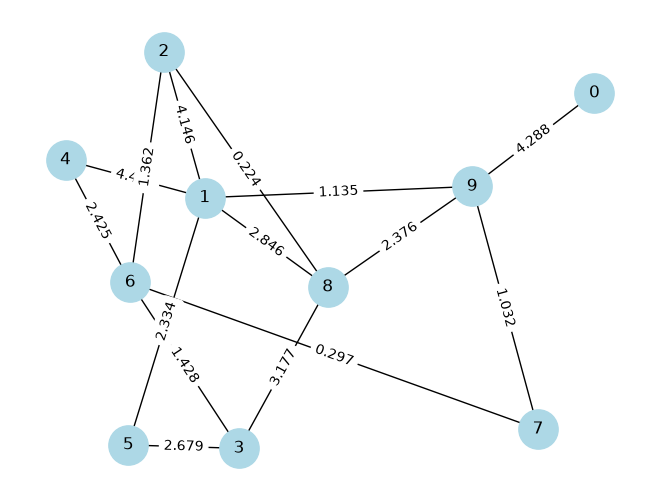

In [10]:
import networkx as nx #You may need to install this using pip install networkx
import random

def random_graph(n, m, max_weight=10):
    # Create an empty undirected graph
    G = nx.Graph()

    # Add n vertices
    G.add_nodes_from(range(n))

    # Generate all possible edges
    possible_edges = [
        (u, v)
        for u in range(n)
        for v in range(u + 1, n)
    ]

    # Make sure there aren't more edges than possible
    if m > len(possible_edges):
        raise ValueError("Too many edges for the given number of vertices.")

    # Randomly select m distinct edges
    edges = random.sample(possible_edges, m)

    # Assign each edge a random nonnegative weight
    for u, v in edges:
        weight = random.uniform(0, max_weight)
        G.add_edge(u, v, weight=weight)

    return G

G = random_graph(10, 15, 5) #Use this to generate the graph. The formula is (Number on nodes, Number of Edges, Max weight of all edges).

import matplotlib.pyplot as plt #We need this to draw the graph.

pos = nx.spring_layout(G) #This edits the layout for the graph.

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color='lightblue',
    node_size=800
)

# Display edge weights
edge_labels = nx.get_edge_attributes(G, 'weight') #You can shorten the weight values by using round(edge_labels, 2) to round the weights to 2 decimal places.
rounded_labels = {edge: round(weight, 3) for edge, weight in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=rounded_labels)

plt.show()

#You can draw different layouts by using nx.circular_layout(G), nx.random_layout(G), nx.shell_layout(G), nx.spectral_layout(G).